# 04 Segmentation (BQ4): R version

**BQ4:** Which groups of customers and products behave differently, and how much revenue does each group bring?

- **Part A, customers:** RFM scores and segments, then k-means on recency, frequency and monetary value.
- **Part B, products:** ABC classification, then k-means on sales, reach, price and seasonality.

Same questions, data and definitions as `04_segmentation_py.ipynb` (see it for the full description).
RFM scores, segments and ABC classes must match exactly; k-means should reach the same solution.

## Setup and data

In [18]:
suppressPackageStartupMessages({
  library(arrow); library(dplyr); library(tidyr); library(ggplot2); library(scales); library(cluster)
})
options(dplyr.summarise.inform = FALSE, scipen = 999, digits = 4, width = 140,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

START <- as.POSIXct("2010-12-01", tz = "UTC")
END   <- as.POSIXct("2011-12-01", tz = "UTC")    # also the RFM reference date
SEED  <- 42
K_RANGE <- 2:8

read_tbl <- function(name) {
  read_parquet(file.path(proc, paste0(name, ".parquet"))) |>
    mutate(date = as.Date(date)) |>
    filter(line_type == "product", invoice_date >= START, invoice_date < END)   # T5, T6
}
prod <- read_tbl("sales_clean")
canc <- read_tbl("cancellations")
invisible(gc())
cat(sprintf("Year 2 product lines: %s   cancellation lines: %s\n", comma(nrow(prod)), comma(nrow(canc))))
cat(sprintf("Gross £%s   cancelled £%s   net £%s\n", comma(sum(prod$revenue)),
            comma(-sum(canc$revenue)), comma(sum(prod$revenue) + sum(canc$revenue))))

Year 2 product lines: 497,787   cancellation lines: 8,321
Gross £9,632,728   cancelled £301,810   net £9,330,919


# Part A: Customer segmentation

In [19]:
ref <- as.Date(END)
c_cust <- canc |> filter(!is.na(customer_id)) |>
  group_by(customer_id) |> summarise(cancelled = -sum(revenue))

cust_all <- prod |> filter(has_customer) |>
  group_by(customer_id) |>
  summarise(last_buy = max(date), frequency = n_distinct(date),
            gross = sum(revenue), uk_share = mean(is_uk)) |>
  left_join(c_cust, by = "customer_id") |>
  mutate(cancelled = coalesce(cancelled, 0),
         monetary = round(gross - cancelled, 2),   # to the penny: removes float residue
         recency_days = as.numeric(ref - last_buy))
cust <- cust_all |> filter(monetary > 0) |> arrange(customer_id)
cat(sprintf("Customers in Year 2: %s   used: %s (dropped %d with net revenue <= 0)\n\n",
            comma(nrow(cust_all)), comma(nrow(cust)), nrow(cust_all) - nrow(cust)))
summary(cust[, c("recency_days", "frequency", "monetary")])

Customers in Year 2: 4,293   used: 4,280 (dropped 13 with net revenue <= 0)



  recency_days     frequency         monetary       
 Min.   :  1.0   Min.   :  1.00   Min.   :     2.9  
 1st Qu.: 16.0   1st Qu.:  1.00   1st Qu.:   294.8  
 Median : 49.0   Median :  2.00   Median :   634.5  
 Mean   : 91.5   Mean   :  3.73   Mean   :  1853.2  
 3rd Qu.:146.0   3rd Qu.:  4.00   3rd Qu.:  1544.1  
 Max.   :365.0   Max.   :125.00   Max.   :267050.0  

## A1. RFM scores and segments

In [20]:
quintile <- function(x) as.integer(ceiling(5 * rank(x, ties.method = "first") / length(x)))

SEG_ORDER <- c("Champions", "Loyal", "New or promising", "Needs attention", "At risk", "Hibernating")
cust <- cust |>
  mutate(R = quintile(-recency_days), F = quintile(frequency), M = quintile(monetary),
         rfm_segment = case_when(
           R >= 4 & F >= 4 ~ "Champions",
           R >= 3 & F >= 3 ~ "Loyal",
           R >= 4 & F <= 2 ~ "New or promising",
           R == 3 & F <= 2 ~ "Needs attention",
           R <= 2 & F >= 3 ~ "At risk",
           TRUE            ~ "Hibernating"),
         rfm_segment = factor(rfm_segment, levels = SEG_ORDER))

seg <- cust |>
  group_by(rfm_segment) |>
  summarise(customers = n(), revenue = sum(monetary),
            median_recency = median(recency_days), median_frequency = median(frequency),
            median_monetary = median(monetary)) |>
  mutate(customer_share = customers / sum(customers), revenue_share = revenue / sum(revenue)) |>
  relocate(customer_share, .after = customers) |> relocate(revenue_share, .after = revenue)

cat("Score check (each score 1-5 should hold about 20% of customers):\n")
print(rbind(R = table(cust$R), F = table(cust$F), M = table(cust$M)))
cat("\n"); print(as.data.frame(seg), digits = 4)

Score check (each score 1-5 should hold about 20% of customers):
    1   2   3   4   5
R 856 856 856 856 856
F 856 856 856 856 856
M 856 856 856 856 856

       rfm_segment customers customer_share revenue revenue_share median_recency median_frequency median_monetary
1        Champions      1087        0.25397 5400466       0.68089             11                6          2128.8
2            Loyal       814        0.19019 1065953       0.13440             38                3           817.8
3 New or promising       333        0.07780  136093       0.01716             17                1           301.3
4  Needs attention       334        0.07804  148962       0.01878             51                1           324.5
5          At risk       667        0.15584  737699       0.09301            135                3           711.4
6      Hibernating      1045        0.24416  442310       0.05577            225                1           253.1


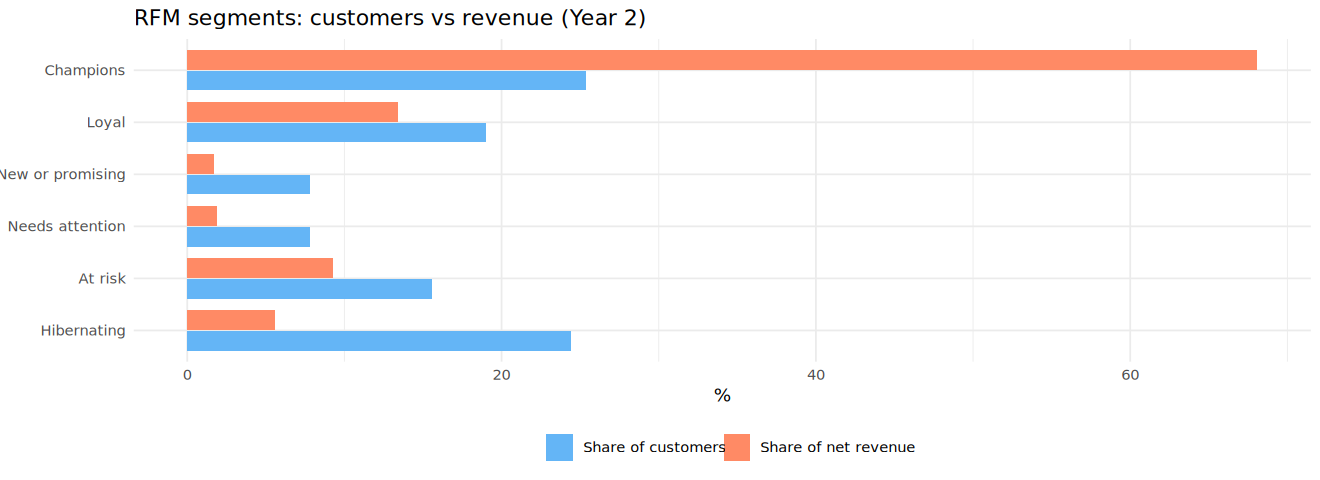

In [21]:
p_seg <- seg |>
  select(rfm_segment, `Share of customers` = customer_share, `Share of net revenue` = revenue_share) |>
  pivot_longer(-rfm_segment) |>
  ggplot(aes(x = value * 100, y = factor(rfm_segment, levels = rev(SEG_ORDER)), fill = name)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  scale_fill_manual(values = c("Share of customers" = "#64B5F6", "Share of net revenue" = "#FF8A65")) +
  labs(x = "%", y = NULL, fill = NULL, title = "RFM segments: customers vs revenue (Year 2)") +
  theme_minimal(base_size = 11) + theme(legend.position = "bottom")
ggsave(file.path(fig, "bq4_rfm_segments_r.png"), p_seg, width = 10, height = 4.5, dpi = 150)
p_seg

## A2. K-means: choosing the number of clusters

Inputs: log(recency), log(frequency), log(monetary), standardised with the population SD (as Python's scaler).
50 random starts per k; `kmeans()` uses the Hartigan–Wong algorithm, Python uses Lloyd's, so both should reach the same optimum.

In [22]:
standardise <- function(df) as.data.frame(lapply(df, function(x) (x - mean(x)) / sqrt(mean((x - mean(x))^2))))

Xc <- standardise(log(cust[, c("recency_days", "frequency", "monetary")]))

k_selection <- function(X) {
  d <- dist(X)
  do.call(rbind, lapply(K_RANGE, function(k) {
    set.seed(SEED)
    km <- kmeans(X, centers = k, nstart = 50, iter.max = 100)
    data.frame(k = k, within_ss = km$tot.withinss,
               silhouette = mean(silhouette(km$cluster, d)[, "sil_width"]))
  }))
}
ksel_c <- k_selection(Xc)
print(ksel_c, digits = 6, row.names = FALSE)

 k within_ss silhouette
 2   6433.21   0.426813
 3   4959.97   0.326494
 4   3937.15   0.337322
 5   3365.13   0.316164
 6   2906.89   0.310586
 7   2637.16   0.311460
 8   2419.95   0.304724


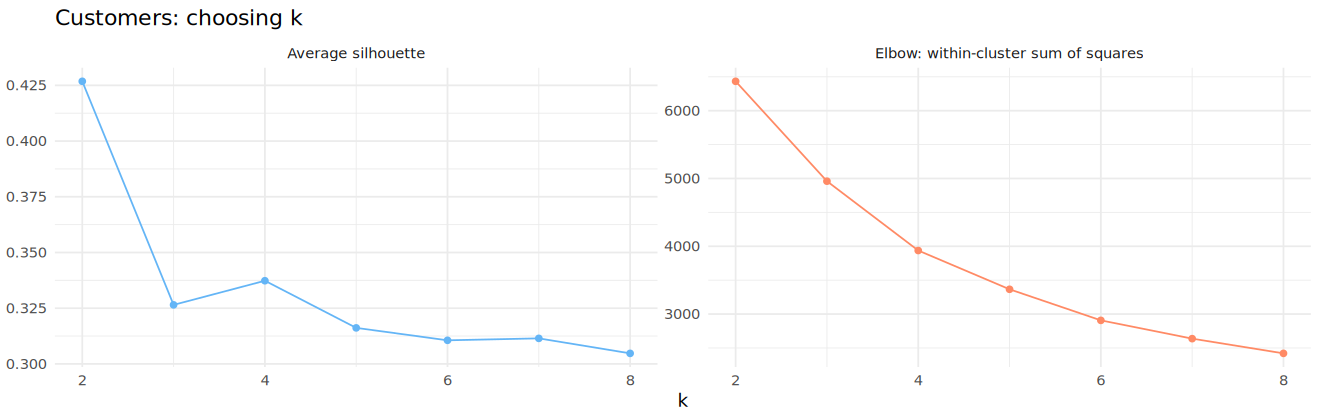

In [23]:
plot_k <- function(ksel, title, file) {
  p <- ksel |>
    pivot_longer(-k) |>
    mutate(name = recode(name, within_ss = "Elbow: within-cluster sum of squares",
                         silhouette = "Average silhouette")) |>
    ggplot(aes(k, value, colour = name)) + geom_line() + geom_point() +
    facet_wrap(~name, scales = "free_y") +
    scale_colour_manual(values = c("#64B5F6", "#FF8A65"), guide = "none") +
    labs(title = title, x = "k", y = NULL) + theme_minimal(base_size = 11)
  ggsave(file.path(fig, file), p, width = 11, height = 3.5, dpi = 150)
  p
}
options(repr.plot.width = 11, repr.plot.height = 3.5)
plot_k(ksel_c, "Customers: choosing k", "bq4_customer_k_r.png")

## A3. Final customer clusters (numbered by average net revenue, 1 = highest)

In [24]:
K_CUST <- 4

fit_final <- function(X, k, order_by) {
  set.seed(SEED)
  km <- kmeans(X, centers = k, nstart = 50, iter.max = 100)
  rank_by <- rank(-tapply(order_by, km$cluster, mean), ties.method = "first")
  list(cluster = unname(rank_by[as.character(km$cluster)]), wss = km$tot.withinss)
}

fc <- fit_final(Xc, K_CUST, cust$monetary)
cust$cluster <- fc$cluster
cat(sprintf("k = %d   within-cluster SS: %s\n\n", K_CUST, format(round(fc$wss, 2), big.mark = ",", nsmall = 2)))

prof_c <- cust |>
  group_by(cluster) |>
  summarise(customers = n(), revenue = sum(monetary),
            median_recency = median(recency_days), median_frequency = median(frequency),
            median_monetary = median(monetary), uk_share = mean(uk_share)) |>
  mutate(customer_share = customers / sum(customers), revenue_share = revenue / sum(revenue)) |>
  relocate(customer_share, .after = customers) |> relocate(revenue_share, .after = revenue)
print(as.data.frame(prof_c), digits = 4)

k = 4   within-cluster SS: 3,937.15

  cluster customers customer_share revenue revenue_share median_recency median_frequency median_monetary uk_share
1       1       735         0.1717 5160139       0.65059              9                8          3315.7   0.8871
2       2      1238         0.2893 1903779       0.24003             55                3          1186.1   0.8998
3       3       798         0.1864  371453       0.04683             15                2           394.5   0.9160
4       4      1509         0.3526  496111       0.06255            181                1           272.4   0.9105


Customers by cluster and RFM segment:
       rfm_segment
cluster Champions Loyal New or promising Needs attention At risk Hibernating  Sum
    1         697    33                1               0       4           0  735
    2         274   467                8              34     421          34 1238
    3         116   286              322              74       0           0  798
    4           0    28                2             226     242        1011 1509
    Sum      1087   814              333             334     667        1045 4280

  cluster recency_days frequency monetary
1       1       -1.221     1.537    1.365
2       2        0.162     0.412    0.476
3       3       -0.836    -0.467   -0.483
4       4        0.904    -0.839   -0.800


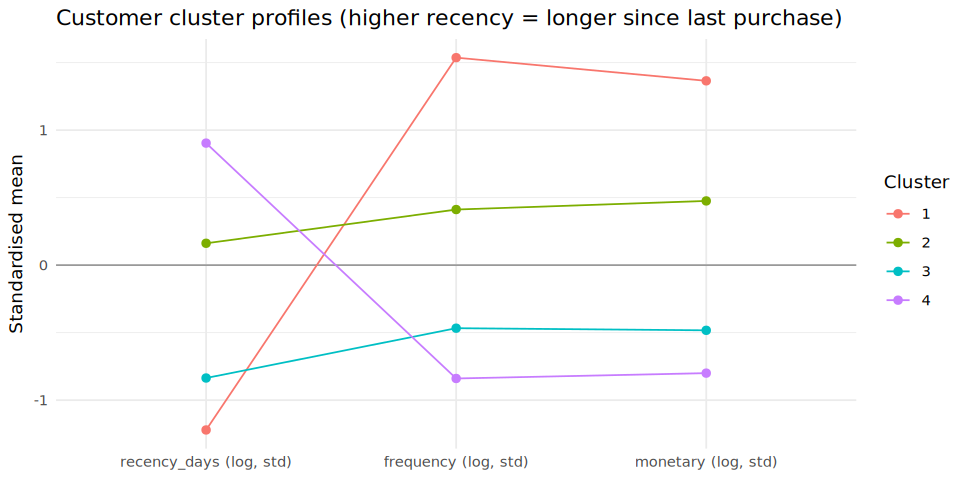

In [25]:
cat("Customers by cluster and RFM segment:\n")
print(addmargins(table(cluster = cust$cluster, rfm_segment = cust$rfm_segment)))

centres <- Xc |> mutate(cluster = cust$cluster) |> group_by(cluster) |> summarise(across(everything(), mean))
cat("\n"); print(as.data.frame(centres), digits = 3)

p_cc <- centres |>
  pivot_longer(-cluster) |>
  mutate(name = factor(paste(name, "(log, std)"), levels = paste(names(Xc), "(log, std)"))) |>
  ggplot(aes(name, value, colour = factor(cluster), group = cluster)) +
  geom_hline(yintercept = 0, colour = "grey60") + geom_line() + geom_point(size = 2) +
  labs(x = NULL, y = "Standardised mean", colour = "Cluster",
       title = "Customer cluster profiles (higher recency = longer since last purchase)") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq4_customer_clusters_r.png"), p_cc, width = 8, height = 4, dpi = 150)
options(repr.plot.width = 8, repr.plot.height = 4); p_cc

# Part B: Product segmentation

In [26]:
c_item <- canc |> group_by(stock_code) |> summarise(cancelled = -sum(revenue))

items_all <- prod |>
  mutate(q4_rev = if_else(as.integer(format(invoice_date, "%m")) >= 10, revenue, 0)) |>
  group_by(stock_code) |>
  summarise(product = first(product_name), gross = sum(revenue), q4_rev = sum(q4_rev),
            orders = n_distinct(invoice), customers = n_distinct(customer_id, na.rm = TRUE),
            price = median(price)) |>
  left_join(c_item, by = "stock_code") |>
  mutate(cancelled = coalesce(cancelled, 0), net = round(gross - cancelled, 2),
         q4_share = q4_rev / gross, cancel_rate = pmin(pmax(cancelled / gross, 0), 1))
items <- items_all |> filter(net > 0)
cat(sprintf("Products sold in Year 2: %s   with positive net revenue: %s\n\n",
            comma(nrow(items_all)), comma(nrow(items))))
summary(items[, c("net", "orders", "customers", "price", "q4_share", "cancel_rate")])

Products sold in Year 2: 3,905   with positive net revenue: 3,896



      net                orders         customers         price           q4_share      cancel_rate    
 Min.   :     0.42   Min.   :   1.0   Min.   :  0.0   Min.   :  0.04   Min.   :0.000   Min.   :0.0000  
 1st Qu.:   120.57   1st Qu.:  15.0   1st Qu.:  7.0   1st Qu.:  1.25   1st Qu.:0.177   1st Qu.:0.0000  
 Median :   646.32   Median :  61.5   Median : 33.0   Median :  2.10   Median :0.307   Median :0.0000  
 Mean   :  2395.08   Mean   : 126.5   Mean   : 66.2   Mean   :  3.59   Mean   :0.371   Mean   :0.0211  
 3rd Qu.:  2085.53   3rd Qu.: 158.0   3rd Qu.: 90.0   3rd Qu.:  4.13   3rd Qu.:0.505   3rd Qu.:0.0136  
 Max.   :158569.32   Max.   :2132.0   Max.   :873.0   Max.   :165.00   Max.   :1.000   Max.   :0.9580  

## B1. ABC classification (A = first 80% of net revenue, B = next 15%, C = last 5%)

In [27]:
items <- items |>
  arrange(desc(net), stock_code) |>
  mutate(cum_share = cumsum(net) / sum(net),
         abc = case_when(cum_share <= 0.80 ~ "A", cum_share <= 0.95 ~ "B", TRUE ~ "C"))

abc <- items |>
  group_by(abc) |>
  summarise(products = n(), revenue = sum(net), median_price = median(price),
            median_customers = median(customers)) |>
  mutate(product_share = products / sum(products), revenue_share = revenue / sum(revenue)) |>
  relocate(product_share, .after = products) |> relocate(revenue_share, .after = revenue)
print(as.data.frame(abc), digits = 4)

  abc products product_share revenue revenue_share median_price median_customers
1   A      837        0.2148 7462445        0.7997         2.55              166
2   B      979        0.2513 1402191        0.1503         1.65               64
3   C     2080        0.5339  466597        0.0500         2.10                8


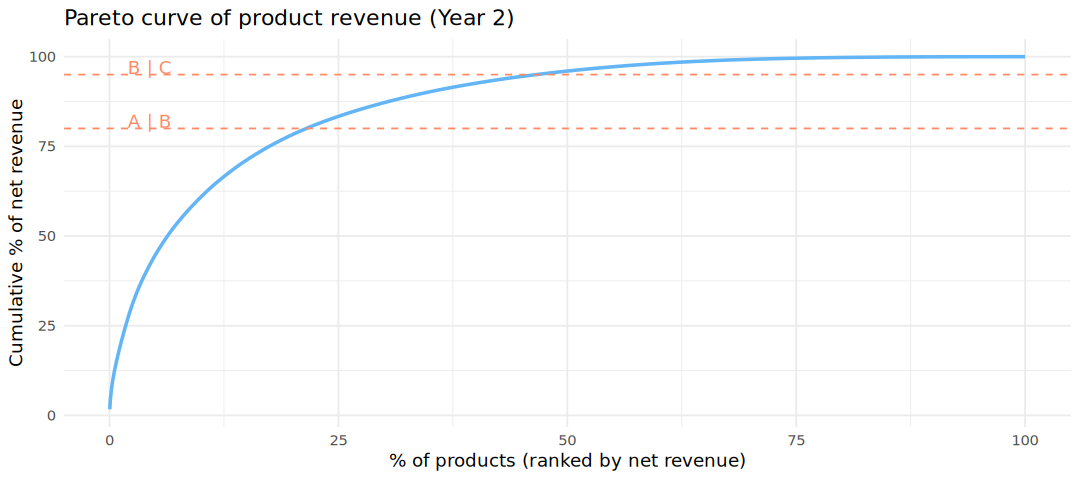

In [28]:
p_abc <- items |>
  mutate(pct_products = row_number() / n() * 100) |>
  ggplot(aes(pct_products, cum_share * 100)) +
  geom_line(colour = "#64B5F6", linewidth = 1) +
  geom_hline(yintercept = c(80, 95), colour = "#FF8A65", linetype = "dashed") +
  annotate("text", x = 2, y = c(82, 97), label = c("A | B", "B | C"), colour = "#FF8A65", hjust = 0) +
  labs(x = "% of products (ranked by net revenue)", y = "Cumulative % of net revenue",
       title = "Pareto curve of product revenue (Year 2)") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq4_abc_pareto_r.png"), p_abc, width = 9, height = 4, dpi = 150)
options(repr.plot.width = 9, repr.plot.height = 4); p_abc

## B2. Product clustering (products with at least 20 orders)

Products clustered: 2,798
 k within_ss silhouette
 2   7887.90   0.267167
 3   6288.28   0.281248
 4   5053.68   0.278009
 5   4421.68   0.263561
 6   3996.79   0.241653
 7   3702.06   0.237731
 8   3419.47   0.238458


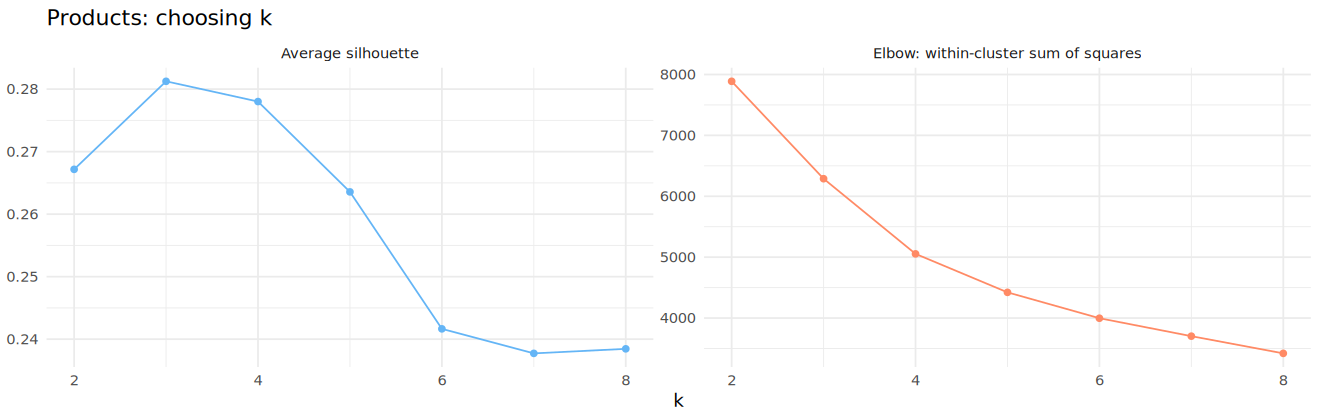

In [29]:
pc <- items |> filter(orders >= 20) |> arrange(stock_code)
Xp <- standardise(data.frame(log_net = log(pc$net), log_customers = log1p(pc$customers),
                             log_price = log(pc$price), q4_share = pc$q4_share))
cat(sprintf("Products clustered: %s\n", comma(nrow(pc))))
ksel_p <- k_selection(Xp)
print(ksel_p, digits = 6, row.names = FALSE)
options(repr.plot.width = 11, repr.plot.height = 3.5)
plot_k(ksel_p, "Products: choosing k", "bq4_product_k_r.png")

In [30]:
K_PROD <- 4
fp <- fit_final(Xp, K_PROD, pc$net)
pc$cluster <- fp$cluster
cat(sprintf("k = %d   within-cluster SS: %s\n\n", K_PROD, format(round(fp$wss, 2), big.mark = ",", nsmall = 2)))

prof_p <- pc |>
  group_by(cluster) |>
  summarise(products = n(), revenue = sum(net), median_net = median(net),
            median_customers = median(customers), median_price = median(price),
            mean_q4_share = mean(q4_share), mean_cancel_rate = mean(cancel_rate),
            share_class_A = mean(abc == "A")) |>
  mutate(product_share = products / sum(products), revenue_share = revenue / sum(revenue)) |>
  relocate(product_share, .after = products) |> relocate(revenue_share, .after = revenue)
print(as.data.frame(prof_p), digits = 4)

k = 4   within-cluster SS: 5,053.68

  cluster products product_share revenue revenue_share median_net median_customers median_price mean_q4_share mean_cancel_rate
1       1      884        0.3159 7193524       0.77902     4912.4              148         2.95        0.2880          0.02166
2       2      470        0.1680  902749       0.09776     1321.0               57         2.08        0.7519          0.02093
3       3      793        0.2834  779618       0.08443      761.5               55         0.83        0.2483          0.01426
4       4      651        0.2327  358220       0.03879      424.6               17         2.95        0.2923          0.01909
  share_class_A
1       0.79751
2       0.19787
3       0.03783
4       0.00768


Example products per cluster (highest net revenue):
  Cluster 1: REGENCY CAKESTAND 3 TIER; PARTY BUNTING; WHITE HANGING HEART T-LIGHT HO
  Cluster 2: ROTATING SILVER ANGELS T-LIGHT; RED WOOLLY HOTTIE WHITE HEART.; HAND WARMER BIRD DESIGN
  Cluster 3: PACK OF 12 LONDON TISSUES; PLACE SETTING WHITE HEART; BROCADE RING PURSE
  Cluster 4: CAMOUFLAGE DESIGN TEDDY; CHILDRENS CUTLERY RETROSPOT RE; VINTAGE BLUE KITCHEN CABINET


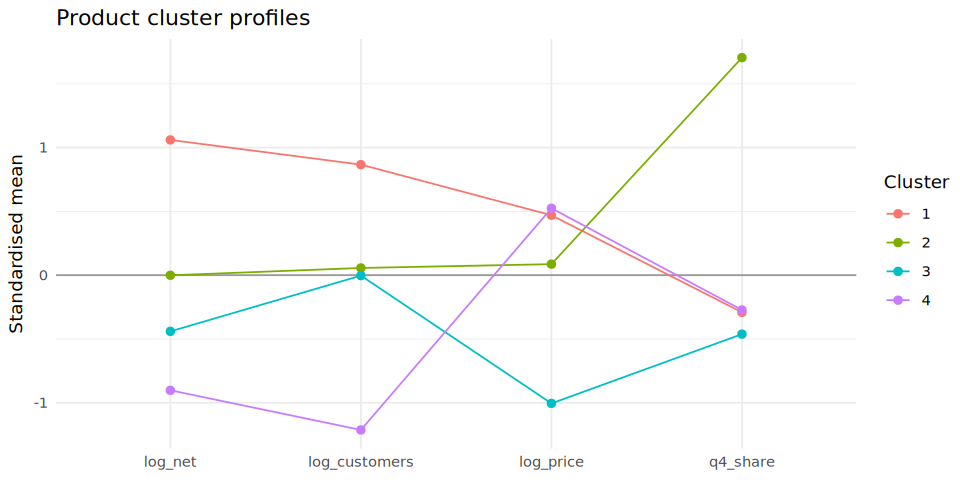

In [31]:
centres_p <- Xp |> mutate(cluster = pc$cluster) |> group_by(cluster) |> summarise(across(everything(), mean))
p_pc <- centres_p |>
  pivot_longer(-cluster) |>
  mutate(name = factor(name, levels = names(Xp))) |>
  ggplot(aes(name, value, colour = factor(cluster), group = cluster)) +
  geom_hline(yintercept = 0, colour = "grey60") + geom_line() + geom_point(size = 2) +
  labs(x = NULL, y = "Standardised mean", colour = "Cluster", title = "Product cluster profiles") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq4_product_clusters_r.png"), p_pc, width = 8, height = 4, dpi = 150)

cat("Example products per cluster (highest net revenue):\n")
for (c in seq_len(K_PROD)) {
  top <- pc |> filter(cluster == c) |> slice_max(net, n = 3, with_ties = FALSE)
  cat(sprintf("  Cluster %d: %s\n", c, paste(substr(top$product, 1, 30), collapse = "; ")))
}
options(repr.plot.width = 8, repr.plot.height = 4); p_pc

## Checks against Python

The dashboard CSVs come from the Python notebook. Here R writes its own customer table to a temporary file
and compares it with Python's `customer_rfm.csv`, if that file exists.

In [32]:
py_file <- file.path(root, "reports", "dashboard_data", "customer_rfm.csv")
if (file.exists(py_file)) {
  py <- read.csv(py_file)
  chk <- cust |> select(customer_id, R, F, M, rfm_segment, cluster) |>
    inner_join(py, by = "customer_id", suffix = c("_r", "_py"))
  cat(sprintf("Customers compared: %s\n", comma(nrow(chk))))
  cat(sprintf("Identical R / F / M scores: %s / %s / %s\n",
              all(chk$R_r == chk$R_py), all(chk$F_r == chk$F_py), all(chk$M_r == chk$M_py)))
  cat(sprintf("Identical RFM segments: %s\n", all(as.character(chk$rfm_segment_r) == chk$rfm_segment_py)))
  cat(sprintf("Identical k-means clusters: %.1f%% of customers\n", 100 * mean(chk$cluster_r == chk$cluster_py)))
} else {
  cat("Run 04_segmentation_py.ipynb first to create customer_rfm.csv.\n")
}

Customers compared: 4,280
Identical R / F / M scores: TRUE / TRUE / TRUE
Identical RFM segments: TRUE
Identical k-means clusters: 99.6% of customers
